In [1]:
import tensorflow as tf

(X_train, y_train), (X_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: (60000, 28, 28)
Testing images: (10000, 28, 28)


In [3]:
import numpy as np
# Normalize pixel values from 0–255 to 0–1
X_train = X_train.astype("float32") / 255.0
X_test = X_test.astype("float32") / 255.0

# Add channel dimension for grayscale images
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]

print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("Training labels:", y_train.shape)

Training shape: (60000, 28, 28, 1)
Testing shape: (10000, 28, 28, 1)
Training labels: (60000,)


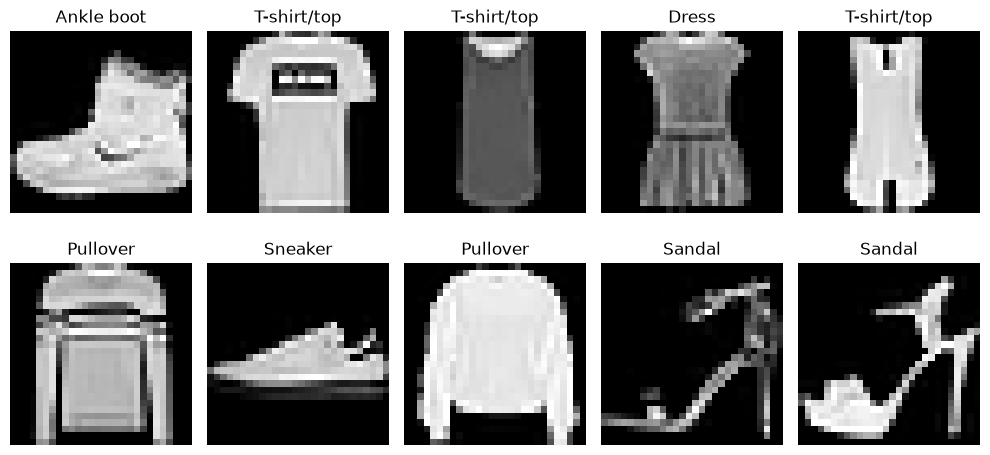

In [ ]:
import matplotlib.pyplot as plt

class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

plt.figure(figsize=(10, 5))

for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i].squeeze(), cmap="gray")
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

print("Dataset cache folder:", os.path.expanduser("~/.keras/datasets"))

print("\nFiles:")
print(os.listdir(os.path.expanduser("~/.keras/datasets")))

Dataset cache folder: C:\Users\Sheher Bano/.keras/datasets

Files:
['fashion-mnist']


In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Conv2D, MaxPooling2D, Flatten, Dense

cnn = Sequential([
    Input(shape=(28, 28, 1)),

    Conv2D(32, kernel_size=3, activation="relu"),
    MaxPooling2D(pool_size=2),

    Conv2D(64, kernel_size=3, activation="relu"),
    MaxPooling2D(pool_size=2),

    Flatten(),
    Dense(64, activation="relu"),
    Dense(10, activation="softmax")
])

cnn.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

history = cnn.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.2
)

Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 14ms/step - accuracy: 0.8021 - loss: 0.5563 - val_accuracy: 0.8567 - val_loss: 0.4014
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.8717 - loss: 0.3600 - val_accuracy: 0.8769 - val_loss: 0.3379
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8871 - loss: 0.3120 - val_accuracy: 0.8840 - val_loss: 0.3182
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 13ms/step - accuracy: 0.8999 - loss: 0.2782 - val_accuracy: 0.8958 - val_loss: 0.2880
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9065 - loss: 0.2526 - val_accuracy: 0.9006 - val_loss: 0.2725


In [ ]:
test_loss, test_accuracy = cnn.evaluate(X_test, y_test, verbose=0)

print("Test Loss:", test_loss)
print("Test Accuracy:", test_accuracy * 100, "%")

Test Loss: 0.2865968942642212
Test Accuracy: 89.5900011062622 %


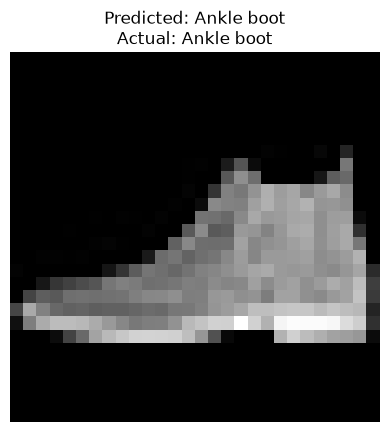

Predicted: Ankle boot
Actual: Ankle boot
Confidence: 98.63 %


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

index = 0

prediction = cnn.predict(X_test[index:index+1], verbose=0)
predicted_class = np.argmax(prediction[0])
actual_class = y_test[index]

plt.imshow(X_test[index].squeeze(), cmap="gray")
plt.title(
    f"Predicted: {class_names[predicted_class]}\n"
    f"Actual: {class_names[actual_class]}"
)
plt.axis("off")
plt.show()

print("Predicted:", class_names[predicted_class])
print("Actual:", class_names[actual_class])
print("Confidence:", round(float(np.max(prediction)) * 100, 2), "%")

In [ ]:
from sklearn.metrics import confusion_matrix, classification_report
import numpy as np

y_pred_probs = cnn.predict(X_test, verbose=0)
y_pred = np.argmax(y_pred_probs, axis=1)

print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

Confusion Matrix:
[[846   0  26  33   7   0  74   0  14   0]
 [  1 966   0  24   4   0   3   0   2   0]
 [ 14   0 835  13  85   0  49   0   4   0]
 [ 11   0   8 920  28   0  28   0   5   0]
 [  0   1  39  35 873   0  49   0   3   0]
 [  0   0   0   0   0 976   0  17   1   6]
 [140   0  84  34  90   0 632   1  19   0]
 [  0   0   0   0   0  11   0 971   1  17]
 [  0   1   1   3   1   1   3   5 985   0]
 [  0   0   0   0   0   5   0  39   1 955]]

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.85      0.84      1000
     Trouser       1.00      0.97      0.98      1000
    Pullover       0.84      0.83      0.84      1000
       Dress       0.87      0.92      0.89      1000
        Coat       0.80      0.87      0.84      1000
      Sandal       0.98      0.98      0.98      1000
       Shirt       0.75      0.63      0.69      1000
     Sneaker       0.94      0.97      0.96      1000
         Bag       0.95      0.98      0

In [ ]:
cnn.save("fashion_mnist_cnn.keras")
print("CNN model saved successfully!")

CNN model saved successfully!


In [ ]:
from tensorflow.keras.models import load_model

loaded_cnn = load_model("fashion_mnist_cnn.keras")
print("CNN model loaded successfully!")

CNN model loaded successfully!


In [ ]:
import tensorflow as tf

base_model = tf.keras.applications.MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(96, 96, 3)
)

base_model.trainable = False

print("Pre-trained model loaded!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 6s 1us/step
Pre-trained model loaded!


In [ ]:
import tensorflow as tf

def prepare_images(images):
    # Resize 28×28 to 96×96
    images = tf.image.resize(images, (96, 96))

    # Convert grayscale to 3 channels
    images = tf.image.grayscale_to_rgb(images)

    # MobileNetV2 preprocessing: [0, 1] → [-1, 1]
    images = tf.keras.applications.mobilenet_v2.preprocess_input(
        images * 255.0
    )

    return images

X_train_tl = prepare_images(X_train[:10000])
X_test_tl = prepare_images(X_test[:2000])

print("Training shape:", X_train_tl.shape)
print("Testing shape:", X_test_tl.shape)

Training shape: (10000, 96, 96, 3)
Testing shape: (2000, 96, 96, 3)


In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout

base_model.trainable = False  # Freeze pre-trained layers

tl_model = Sequential([
    Input(shape=(96, 96, 3)),
    base_model,
    GlobalAveragePooling2D(),
    Dense(128, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

tl_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

tl_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_96             │ (None, 3, 3, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,423,242 (9.24 MB)

 Trainable params: 165,258 (645.54 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:
import tensorflow as tf
import gc

tf.keras.backend.clear_session()
gc.collect()

0

In [ ]:
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, GlobalAveragePooling2D, Dense, Dropout

base_model.trainable = False

tl_model = Sequential([
    Input(shape=(96, 96, 3)),
    base_model,
    GlobalAveragePooling2D(),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(10, activation="softmax")
])

tl_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [ ]:
history_tl = tl_model.fit(
    X_train_tl[:2000],
    y_train[:2000],
    epochs=3,
    batch_size=8,
    validation_split=0.2
)

Epoch 1/3
200/200 ━━━━━━━━━━━━━━━━━━━━ 13s 45ms/step - accuracy: 0.6706 - loss: 0.9537 - val_accuracy: 0.7925 - val_loss: 0.5728
Epoch 2/3
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 41ms/step - accuracy: 0.8288 - loss: 0.4806 - val_accuracy: 0.8275 - val_loss: 0.4983
Epoch 3/3
200/200 ━━━━━━━━━━━━━━━━━━━━ 8s 37ms/step - accuracy: 0.8625 - loss: 0.3947 - val_accuracy: 0.8350 - val_loss: 0.4661


In [ ]:
test_loss, test_accuracy = tl_model.evaluate(
    X_test_tl[:500],
    y_test[:500],
    batch_size=8,
    verbose=0
)

print("Test Loss:", test_loss)
print("Test Accuracy:", round(test_accuracy * 100, 2), "%")

Test Loss: 0.4416327178478241
Test Accuracy: 82.8 %


In [ ]:
# Unfreeze the last 20 layers
base_model.trainable = True

for layer in base_model.layers[:-20]:
    layer.trainable = False

# Keep Batch Normalization layers frozen
for layer in base_model.layers:
    if isinstance(layer, tf.keras.layers.BatchNormalization):
        layer.trainable = False

# Recompile with a low learning rate
tl_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Trainable base layers:", sum(
    layer.trainable for layer in base_model.layers
))

Trainable base layers: 13


In [ ]:
history_fine = tl_model.fit(
    X_train_tl[:2000],
    y_train[:2000],
    epochs=3,
    batch_size=8,
    validation_split=0.2
)

Epoch 1/3
200/200 ━━━━━━━━━━━━━━━━━━━━ 34s 135ms/step - accuracy: 0.8256 - loss: 0.5232 - val_accuracy: 0.8250 - val_loss: 0.5305
Epoch 2/3
200/200 ━━━━━━━━━━━━━━━━━━━━ 29s 145ms/step - accuracy: 0.8825 - loss: 0.3380 - val_accuracy: 0.8125 - val_loss: 0.6434
Epoch 3/3
200/200 ━━━━━━━━━━━━━━━━━━━━ 20s 101ms/step - accuracy: 0.8863 - loss: 0.3175 - val_accuracy: 0.8250 - val_loss: 0.6458


In [ ]:
loss_fine, acc_fine = tl_model.evaluate(
    X_test_tl[:500],
    y_test[:500],
    batch_size=8,
    verbose=0
)

print("Fine-tuned test accuracy:", round(acc_fine * 100, 2), "%")

Fine-tuned test accuracy: 83.0 %


In [5]:
import os

print("Current folder:", os.getcwd())

print([
    f for f in os.listdir(".")
    if f.endswith((".keras", ".h5", ".hdf5"))
])

Current folder: d:\NeuraForge\DL\Practice
['breast_cancer_ann.keras', 'fashion_mnist_cnn.keras']


In [6]:
import os

for root, dirs, files in os.walk(r"D:\NeuraForge\DL"):
    for file in files:
        if file.endswith((".keras", ".h5", ".hdf5")):
            print(os.path.join(root, file))

D:\NeuraForge\DL\Practice\breast_cancer_ann.keras
D:\NeuraForge\DL\Practice\fashion_mnist_cnn.keras


In [7]:
files = [
    "model.keras",
    "notes.txt",
    "cnn.h5",
    "data.csv"
]

for file in files:
    if file.endswith((".keras", ".h5", ".hdf5")):
        print(file)

model.keras
cnn.h5


In [9]:
print([
    name for name, obj in globals().items()
    if isinstance(obj, tf.keras.Model)
])

[]


In [10]:
import tensorflow as tf

cnn_model = tf.keras.models.load_model(
    r"D:\NeuraForge\DL\Practice\fashion_mnist_cnn.keras"
)

print("CNN model loaded successfully!")

CNN model loaded successfully!


In [11]:
cnn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │       102,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 365,792 (1.40 MB)

 Trainable params: 121,930 (476.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 243,862 (952.59 KB)

In [12]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)
print("CNN input shape:", cnn_model.input_shape)

X_train shape: (60000, 28, 28, 1)
X_test shape: (10000, 28, 28, 1)
CNN input shape: (None, 28, 28, 1)


In [13]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("MobileNetV2 available:", hasattr(
    tf.keras.applications, "MobileNetV2"
))

TensorFlow version: 2.21.0
MobileNetV2 available: True
